# Elevator dispatch under load
Three dispatch policies, two workloads. Select LOOK or FIFO in the first code cell.
The question is how much time passengers spend waiting and riding.

In [1]:
from pathlib import Path
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
%matplotlib inline

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "run.py").exists())
CASES = {"Basic": ("mixed", "basic"), "Stress": ("stress", "stress")}
LABELS = {"nearest-car": "Nearest car", "direction-aware": "Direction aware", "cost": "Cost"}
MOVEMENT_POLICY = "cost"
STOP_SCHEDULER = "look"  # "look" or "fifo"


def run_directory(workload, building, scheduler=STOP_SCHEDULER):
    scenario = workload if workload == building else f"{workload}-{building}"
    return ROOT / "out" / scenario / scheduler


In [2]:
rows = []
for case, (workload, building) in CASES.items():
    config = json.loads((ROOT / f"examples/configs/{building}.json").read_text())
    count = len(pd.read_csv(ROOT / f"examples/requests/{workload}.csv"))
    for policy, label in LABELS.items():
        path = run_directory(workload, building) / policy / "summary.json"
        summary = json.loads(path.read_text())
        assert summary["configuration"] == config, f"Configuration mismatch: {path}"
        assert summary["completed_passengers"] == count, f"Incomplete run: {path}"
        assert summary["dispatcher"] == policy and summary["stop_scheduler"] == STOP_SCHEDULER
        rows.append({"Scenario": case, "Policy": label, **summary})
results = pd.DataFrame(rows)
setup = results.drop_duplicates("Scenario")
for row in setup.itertuples():
    c = row.configuration
    display(Markdown(f"**{row.Scenario}** · {row.completed_passengers:,} requests · "
                     f"{c['floors']} floors · {c['elevator_count']} cars · {c['capacity']} seats per car"))

**Basic** · 8 requests · 10 floors · 2 cars · 3 seats per car

**Stress** · 1,000 requests · 60 floors · 12 cars · 8 seats per car

One tick is one floor of travel. Boarding and exiting take no time; capacity
is enforced and occupied cars never reverse. Ride time is therefore fixed
by trip distance. Dispatch changes waiting time.

Policies are compared **within each scenario**. Differences between scenarios
may reflect both passenger demand and building configuration.

In [3]:
PAPER, INK, MUTED = "#fbfaf7", "#253247", "#6b7280"
PALETTE = {"Nearest car": "#8695aa", "Direction aware": "#9a7abc", "Cost": "#238b83"}
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans", rc={
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "grid.color": "#e5e7eb", "axes.edgecolor": PAPER, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "figure.dpi": 120})

def show_chart(fig):
    plt.show()
    plt.close(fig)

def policy_bars(metric, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    fig.suptitle(title, fontsize=19, fontweight="bold", x=0, ha="left")
    for ax, case in zip(axes, CASES):
        data = results[results["Scenario"] == case]
        sns.barplot(data=data, x=metric, y="Policy", hue="Policy", order=list(LABELS.values()),
                    palette=PALETTE, legend=False, errorbar=None, ax=ax, width=0.56)
        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", padding=5, color=INK)
        ax.set(title=case, xlabel="Ticks · lower is better", ylabel="")
        ax.set_xlim(0, data[metric].max() * 1.22)
        ax.grid(axis="y", visible=False)
        sns.despine(ax=ax, left=True, bottom=True)
    show_chart(fig)

## The average trip
Total passenger time runs from request to arrival. Each panel has its own
scale so the small workload remains readable.

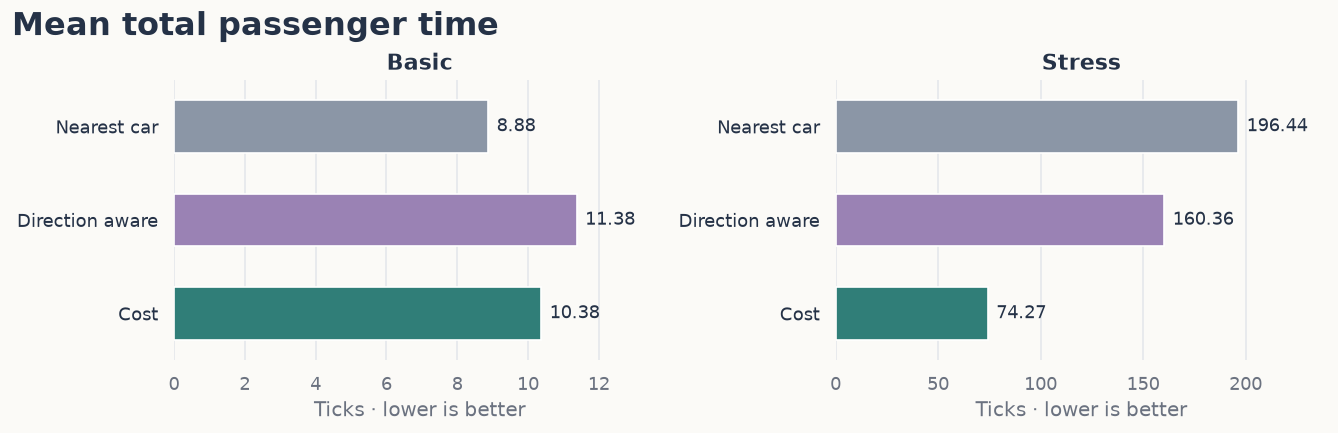

In [4]:
policy_bars("mean_total", "Mean total passenger time")

In [5]:
basic = results[results["Scenario"] == "Basic"].set_index("Policy")
stress = results[results["Scenario"] == "Stress"].set_index("Policy")
for case, data in (("Basic", basic), ("Stress", stress)):
    baseline = data.loc["Nearest car", "mean_total"]
    change = 100 * (data.loc["Cost", "mean_total"] / baseline - 1)
    comparison = (
        f"**{abs(change):.1f}% {'lower' if change < 0 else 'higher'}** than Nearest car"
        if change != 0 else "**the same** as Nearest car"
    )
    display(Markdown(f"**{case}:** Cost's mean total passenger time is {comparison}."))

**Basic:** Cost's mean total passenger time is **16.9% higher** than Nearest car.

**Stress:** Cost's mean total passenger time is **62.2% lower** than Nearest car.

## The passenger who waits longest
A good average can hide a poor experience. Maximum waiting time measures the
longest request-to-boarding delay observed in each run.

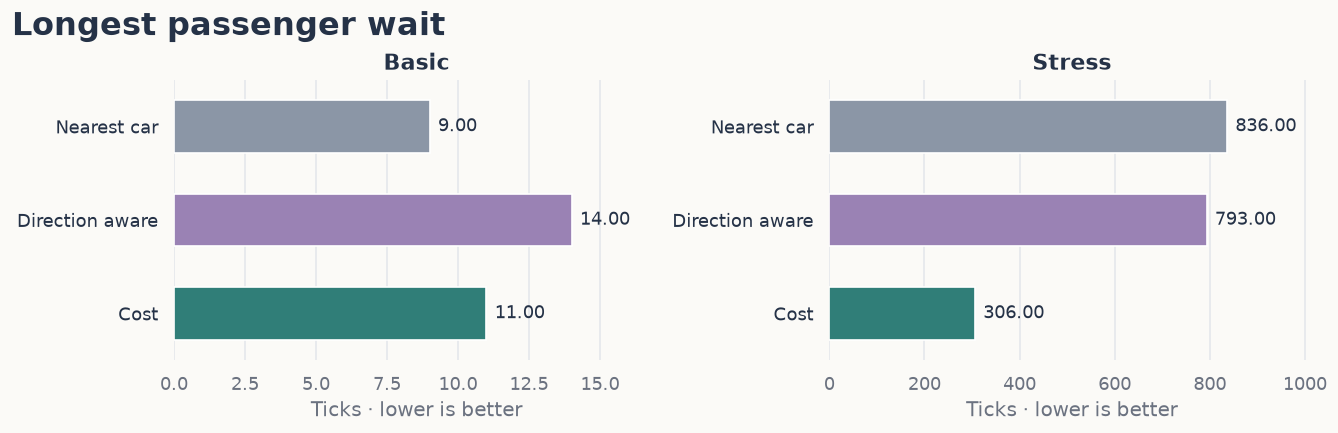

On Stress, the longest wait is **306 ticks** with Cost, compared with **836 ticks** with Nearest car. Minimizing total time does not impose a waiting-time limit.

In [6]:
policy_bars("max_wait", "Longest passenger wait")
display(Markdown(f"On Stress, the longest wait is **{stress.loc['Cost', 'max_wait']:.0f} ticks** "
                 f"with Cost, compared with **{stress.loc['Nearest car', 'max_wait']:.0f} ticks** "
                 "with Nearest car. Minimizing total time does not impose a waiting-time limit."))

## What the fleet does
Each row is one elevator in the Stress run. Color shows its floor at every
recorded tick. A constant band means it stays at the same floor; changing
color shows movement. This shows positions, not passenger occupancy.

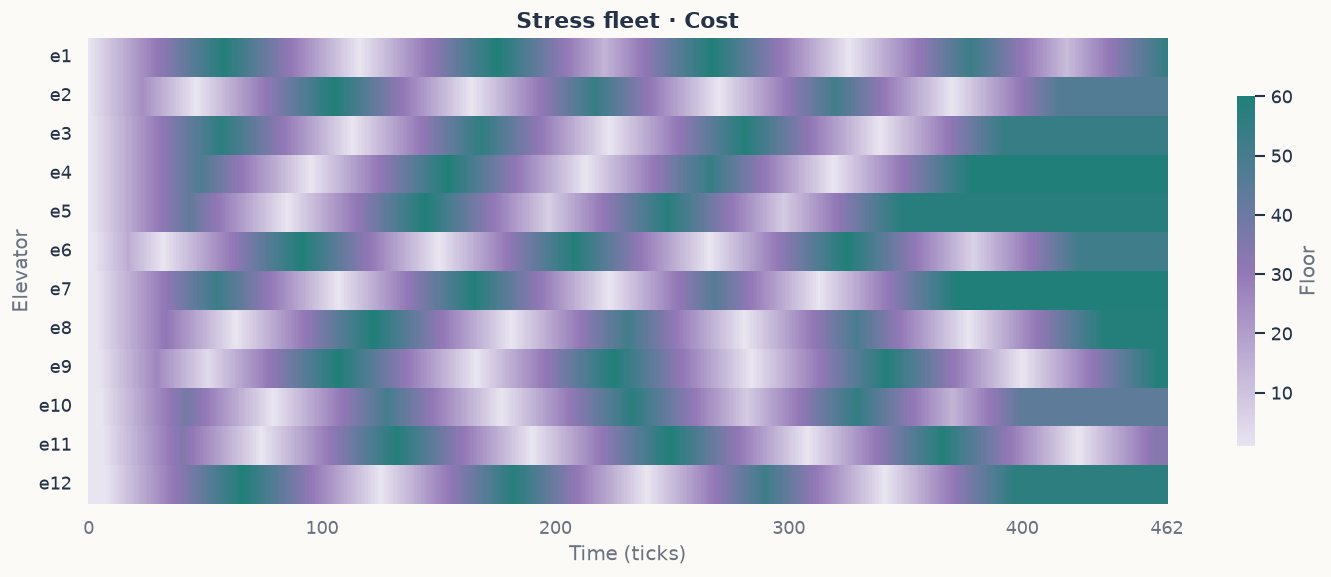

In [7]:
workload, building = CASES["Stress"]
positions = pd.read_csv(run_directory(workload, building) / MOVEMENT_POLICY / "positions.csv")
matrix = positions.set_index("time").T
fig, ax = plt.subplots(figsize=(11, 4.7), layout="constrained")
sns.heatmap(matrix, ax=ax, cmap=sns.blend_palette(["#e8e4f0", "#9277b6", "#207f79"], as_cmap=True),
            vmin=1, vmax=stress.loc[LABELS[MOVEMENT_POLICY], "configuration"]["floors"],
            xticklabels=False, yticklabels=True, cbar_kws={"label": "Floor", "shrink": 0.75})
ticks = sorted(set([0, *range(100, len(positions), 100), len(positions) - 1]))
ax.set_xticks([t + 0.5 for t in ticks], [str(t) for t in ticks], rotation=0)
ax.set(title=f"Stress fleet · {LABELS[MOVEMENT_POLICY]}", xlabel="Time (ticks)", ylabel="Elevator")
ax.tick_params(axis="y", rotation=0)
show_chart(fig)

## LOOK and FIFO
Each pair uses the same dispatcher, requests, and building. Compare mean total
passenger time (waiting plus riding); shorter bars are better. FIFO prioritizes
older trips while LOOK follows its directional sweep. Both support shared rides.

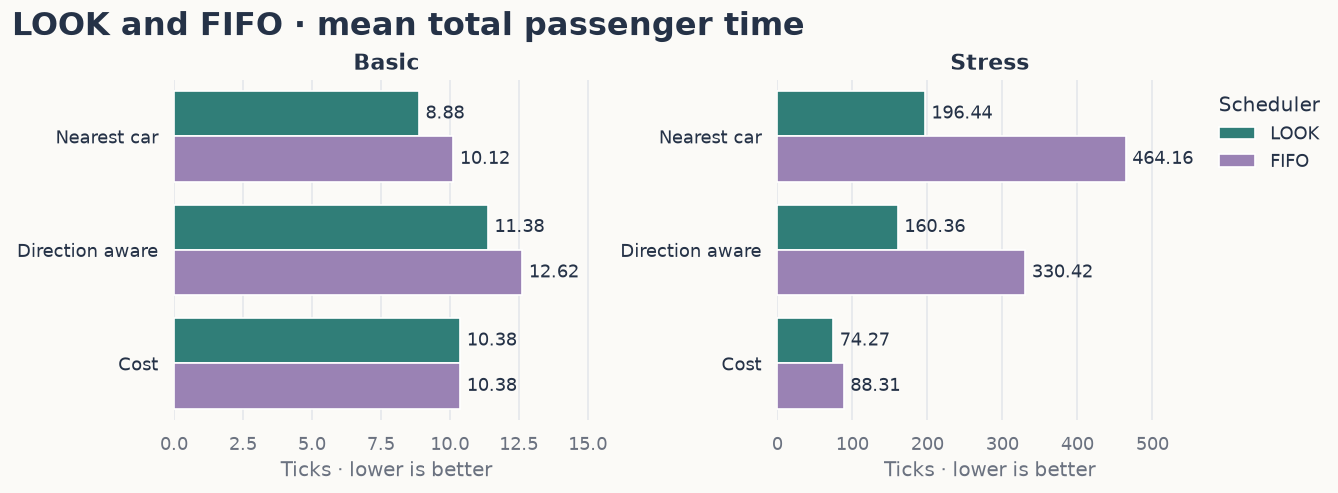

In [8]:
comparison = []
for case, (workload, building) in CASES.items():
    expected = results[results["Scenario"] == case].iloc[0]
    for scheduler in ("look", "fifo"):
        for policy, label in LABELS.items():
            path = run_directory(workload, building, scheduler) / policy / "summary.json"
            summary = json.loads(path.read_text())
            assert summary["configuration"] == expected["configuration"], f"Configuration mismatch: {path}"
            assert summary["completed_passengers"] == expected["completed_passengers"], f"Incomplete run: {path}"
            assert summary["dispatcher"] == policy and summary["stop_scheduler"] == scheduler
            comparison.append({"Scenario": case, "Policy": label,
                               "Scheduler": scheduler.upper(), "Mean total": summary["mean_total"]})
comparison = pd.DataFrame(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
fig.suptitle("LOOK and FIFO · mean total passenger time", fontsize=19, fontweight="bold", x=0, ha="left")
for ax, case in zip(axes, CASES):
    data = comparison[comparison["Scenario"] == case]
    sns.barplot(data=data, x="Mean total", y="Policy", hue="Scheduler",
                order=list(LABELS.values()), hue_order=["LOOK", "FIFO"],
                palette={"LOOK": "#238b83", "FIFO": "#9a7abc"}, errorbar=None, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=4, color=INK)
    ax.set(title=case, xlabel="Ticks · lower is better", ylabel="")
    ax.set_xlim(0, data["Mean total"].max() * 1.22)
    ax.grid(axis="y", visible=False)
    if ax is axes[0]:
        ax.get_legend().remove()
    else:
        ax.legend(title="Scheduler", frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
    sns.despine(ax=ax, left=True, bottom=True)
show_chart(fig)

## Findings

In [9]:
findings = []
for case, data in results.groupby("Scenario", sort=False):
    lowest = data["mean_total"].min()
    winners = data.loc[data["mean_total"] == lowest, "Policy"].tolist()
    findings.append(f"- **{case}:** {', '.join(winners)} achieved the lowest mean total "
                    f"passenger time, **{lowest:.2f} ticks**.")
display(Markdown("\n".join(findings) + "\n\n"
                 "These are two deterministic workloads, not evidence that one policy is always best. "
                 f"Cost makes a greedy decision using arrived requests and current {STOP_SCHEDULER.upper()} plans; "
                 "it has no global optimality guarantee."))

- **Basic:** Nearest car achieved the lowest mean total passenger time, **8.88 ticks**.
- **Stress:** Cost achieved the lowest mean total passenger time, **74.27 ticks**.

These are two deterministic workloads, not evidence that one policy is always best. Cost makes a greedy decision using arrived requests and current LOOK plans; it has no global optimality guarantee.